# 📘 Watt-Seer-Compare: Illuminating Your Energy Footprint
     A Personalized Benchmarking Experience with GenAI
## 🌟 The Quest for "Normal":
Understanding Your Energy Usage in Context
Have you ever looked at your energy bill and wondered, "Is this how much energy a household like mine typically uses?" 

It's a natural question! Understanding whether your energy consumption is within a normal range can be the first step towards identifying potential inefficiencies and embracing energy-saving habits.

This project, "Watt-Seer-Compare," embarks on this quest for understanding. We leverage the power of smart home energy data and the insightful natural language capabilities of Google Gemini to provide you with a personalized benchmarking experience. The features used are RAG, Embeddings, Long context window, few shot prompting.


We'll compare your household's energy usage against similar homes and, most importantly, explain the nuances of these comparisons in a way that's intuitive and actionable. 

In [1]:
!pip uninstall -qqy jupyterlab kfp  # Remove unused conflicting packages
!pip install -qU "google-genai==1.7.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.7/144.7 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.9/100.9 kB 4.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
jupyterlab-lsp 3.10.2 requires jupyterlab<4.0.0a0,>=3.1.0, which is not installed.


In [2]:
from google import genai
from google.genai import types

genai.__version__

'1.7.0'

## 🎯 Unveiling the Data: 
### Our Window into Household Energy Habits
Our analysis is powered by a rich dataset containing detailed energy consumption information for various households. Each data point offers a snapshot of energy use, enriched with contextual details:

🏡 Home ID: A unique identifier, like a digital address, for each household in our study.

🔌 Appliance Type: The specific device consuming energy, ranging from essential appliances like the fridge to comfort systems like the heater and air conditioner.

⚡ Energy Consumption (kWh): The metered energy used by each appliance during a specific time interval, providing a granular view of consumption.

📅 Date + Time: The precise moment each energy reading was recorded, allowing us to analyze patterns across different times and days.

🌡️ Outdoor Temperature (°C): The ambient temperature outside the home at the time of energy use, a crucial factor influencing heating and cooling needs.

☀️ Season: The time of year, helping us understand how seasonal changes impact energy consumption patterns.

👨‍👩‍👧‍👦 Household Size: The number of occupants in the home, a key determinant of overall energy demand.

In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import json #Json format
from IPython.display import Markdown, display
from kaggle_secrets import UserSecretsClient
from sklearn.metrics.pairwise import cosine_similarity #for generating similaties between embeddings
from google.api_core import retry
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

import matplotlib.pyplot as plt
import seaborn as sns

# Set a plotting style (optional)
sns.set_theme(style="whitegrid")

/kaggle/input/smart-home-energy-consumption/smart_home_energy_consumption_large.csv


In [4]:
# Load dataset
df = pd.read_csv('/kaggle/input/smart-home-energy-consumption/smart_home_energy_consumption_large.csv')

if 'df' in locals(): # Only proceed if df was loaded successfully
    # --- Data Cleaning and Preprocessing ---
    # Convert to datetime, handling potential errors
    df['datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], errors='coerce')
    df.dropna(subset=['datetime'], inplace=True) # Remove rows where datetime conversion failed

    # Create Year-Month period column
    df['year_month'] = df['datetime'].dt.to_period('M').astype(str)

    # --- Modified fillna calls ---
    # Handle potential missing values or inconsistencies using assignment
    household_mode = df['Household Size'].mode()
    df['Household Size'] = df['Household Size'].fillna(household_mode[0] if not household_mode.empty else 'Unknown')

    df['Season'] = df['Season'].fillna('Unknown')

    outdoor_temp_median = df['Outdoor Temperature (°C)'].median()
    df['Outdoor Temperature (°C)'] = df['Outdoor Temperature (°C)'].fillna(outdoor_temp_median)

    df['Energy Consumption (kWh)'] = df['Energy Consumption (kWh)'].fillna(0) # Assuming 0 for missing consumption

    print("Dataset shape:", df.shape)
    print("Unique Home IDs:", df['Home ID'].nunique())
    print("Date range:", df['datetime'].min(), "to", df['datetime'].max())
    print("\nSample data:")
    display(df.head())

Dataset shape: (100000, 10)
Unique Home IDs: 500
Date range: 2023-01-01 00:07:00 to 2024-01-01 23:53:00

Sample data:


,Home ID,Appliance Type,Energy Consumption (kWh),Time,Date,Outdoor Temperature (°C),Season,Household Size,datetime,year_month
0,94,Fridge,0.20,21:12,2023-12-02,-1.0,Fall,2,2023-12-02 21:12:00,2023-12
1,435,Oven,0.23,20:11,2023-08-06,31.1,Summer,5,2023-08-06 20:11:00,2023-08
2,466,Dishwasher,0.32,06:39,2023-11-21,21.3,Fall,3,2023-11-21 06:39:00,2023-11
3,496,Heater,3.92,21:56,2023-01-21,-4.2,Winter,1,2023-01-21 21:56:00,2023-01
4,137,Microwave,0.44,04:31,2023-08-26,34.5,Summer,5,2023-08-26 04:31:00,2023-08


The **create_monthly_summaries** function generates textual energy consumption summaries for each home per month. It performs the following steps:


* **Group Data by Home:** It processes the data home by home.
* **Household Size:** Determines the most common household size for each home.
* **Monthly Breakdown:** Groups data by month and calculates total energy consumption, average outdoor temperature, and the most common season.
* **Appliance Breakdown:** Summarizes energy usage by appliance, excluding negligible consumption.
* **Textual Summary:** Creates a summary with key metrics like total consumption, temperature, season, and appliance usage.


The function returns a **DataFrame containing these monthly summaries**, which can be used for further analysis or visualization.



In [5]:
def create_monthly_summaries(input_df):
    """
    Generates textual summaries of energy consumption for each home per month.
    """
    summary_records = []
    print(f"Generating monthly summaries for {input_df['Home ID'].nunique()} unique homes...")

    # Group by Home ID first for efficiency
    for home_id, home_df in input_df.groupby('Home ID'):
        # Determine the most common household size for this home
        # Use .mode()[0] but handle cases where mode() might be empty or have multiple values
        mode_size = home_df['Household Size'].mode()
        household_size = mode_size[0] if not mode_size.empty else "Unknown"

        # Group by month within each home's data
        for period, month_df in home_df.groupby('year_month'):
            total_kwh = month_df['Energy Consumption (kWh)'].sum()
            # Handle potential NaN avg temp if all values are NaN for a month (unlikely but safe)
            avg_temp = month_df['Outdoor Temperature (°C)'].mean()
            avg_temp = round(avg_temp, 1) if pd.notna(avg_temp) else "N/A"

            # Determine the most common season for the month
            mode_season = month_df['Season'].mode()
            season = mode_season[0] if not mode_season.empty else "Unknown"

            # Appliance-wise breakdown
            appliance_breakdown = month_df.groupby('Appliance Type')['Energy Consumption (kWh)'].sum().sort_values(ascending=False)
            # Filter out appliances with 0 or negligible consumption for cleaner summaries
            appliance_breakdown = appliance_breakdown[appliance_breakdown > 0.05]
            appliance_summary_list = [f"{appliance}: {kwh:.1f} kWh" for appliance, kwh in appliance_breakdown.items()]
            appliance_summary = "; ".join(appliance_summary_list) if appliance_summary_list else "No significant appliance usage recorded"

            # Formatted textual summary for embedding and context
            summary_text = (
                f"Home ID {home_id} for Month {period}:\n"
                f"- Total Consumption: {total_kwh:.1f} kWh\n"
                f"- Household Size: {household_size}\n"
                f"- Average Temperature: {avg_temp}°C\n"
                f"- Season: {season}\n"
                f"- Appliance Breakdown: {appliance_summary}"
            )

            # Store detailed data alongside the summary text for potential later use
            summary_records.append({
                "Home ID": home_id,
                "year_month": period,
                "Total kWh": round(total_kwh, 1),
                "Avg Temp": avg_temp,
                "Season": season,
                "Household Size": household_size,
                "Summary Text": summary_text
            })

    summary_df = pd.DataFrame(summary_records)
    print(f"Generated {len(summary_df)} monthly summary records.")
    return summary_df

# Generate the summaries for the entire dataset
summary_df = create_monthly_summaries(df)

# Display a sample of the generated summaries
print("\nSample generated summaries:")

# Pretty display 
styled_df = summary_df.head(5).style.set_properties(**{'text-align': 'center'}).set_table_styles([{'selector': 'th', 'props': [('text-align', 'center')]}]).hide(axis="index")

display(styled_df)


Generating monthly summaries for 500 unique homes...
Generated 6224 monthly summary records.

Sample generated summaries:


Home ID,year_month,Total kWh,Avg Temp,Season,Household Size,Summary Text
1,2023-01,34.900000,15.900000,Winter,3,Home ID 1 for Month 2023-01: - Total Consumption: 34.9 kWh - Household Size: 3 - Average Temperature: 15.9°C - Season: Winter - Appliance Breakdown: Air Conditioning: 18.0 kWh; Heater: 4.6 kWh; Oven: 3.0 kWh; Computer: 3.0 kWh; Lights: 2.1 kWh; Dishwasher: 1.9 kWh; Washing Machine: 1.7 kWh; TV: 0.7 kWh
1,2023-02,28.900000,10.000000,Winter,3,Home ID 1 for Month 2023-02: - Total Consumption: 28.9 kWh - Household Size: 3 - Average Temperature: 10.0°C - Season: Winter - Appliance Breakdown: Heater: 15.6 kWh; Air Conditioning: 4.4 kWh; Oven: 3.1 kWh; Lights: 2.6 kWh; Dishwasher: 1.6 kWh; Washing Machine: 0.9 kWh; TV: 0.7 kWh; Fridge: 0.1 kWh
1,2023-03,38.200000,9.400000,Winter,3,Home ID 1 for Month 2023-03: - Total Consumption: 38.2 kWh - Household Size: 3 - Average Temperature: 9.4°C - Season: Winter - Appliance Breakdown: Heater: 17.9 kWh; Air Conditioning: 4.9 kWh; Microwave: 4.6 kWh; Washing Machine: 3.2 kWh; TV: 3.1 kWh; Oven: 2.6 kWh; Computer: 1.4 kWh; Fridge: 0.5 kWh
1,2023-04,25.500000,11.900000,Spring,3,Home ID 1 for Month 2023-04: - Total Consumption: 25.5 kWh - Household Size: 3 - Average Temperature: 11.9°C - Season: Spring - Appliance Breakdown: Heater: 6.0 kWh; Washing Machine: 3.8 kWh; Microwave: 3.8 kWh; Air Conditioning: 3.6 kWh; Computer: 3.0 kWh; Oven: 1.9 kWh; Lights: 1.7 kWh; TV: 1.6 kWh; Fridge: 0.1 kWh
1,2023-05,32.900000,13.900000,Spring,3,Home ID 1 for Month 2023-05: - Total Consumption: 32.9 kWh - Household Size: 3 - Average Temperature: 13.9°C - Season: Spring - Appliance Breakdown: Heater: 8.8 kWh; Computer: 6.4 kWh; Oven: 4.5 kWh; Air Conditioning: 3.9 kWh; Dishwasher: 3.3 kWh; Lights: 2.8 kWh; TV: 1.7 kWh; Microwave: 0.8 kWh; Fridge: 0.7 kWh


## 🧠 Encoding Understanding: 
### Generating Semantic Embeddings with Gemini

To compare the energy usage patterns of different homes, we'll use the power of Google Gemini to create semantic embeddings. These embeddings are numerical representations that capture the meaning and context of our textual summaries. By comparing these embeddings, we can identify homes with similar energy consumption profiles.


In [6]:

GOOGLE_API_KEY = UserSecretsClient().get_secret("GOOGLE_API_KEY")

client = genai.Client(api_key=GOOGLE_API_KEY)



* **Efficient Embedding Generation:** The code provides functions to generate text embeddings in batches for efficiency.
* **Retry Mechanism:** It includes a robust retry mechanism (@retry.Retry) to handle common API errors during embedding.
* **embed_content_with_retry:** This function calls the embedding API with the specified retry logic.
* **generate_embeddings_efficiently:** This function takes a DataFrame of summaries, batches them, and uses embed_content_with_retry to generate embeddings.


In [7]:
from google.api_core import exceptions as api_core_exceptions
import time # Optional for delays


# Define Embedding Model (Using the one from user's code)
EMBEDDING_MODEL_NAME = "models/text-embedding-004"
# ---------------------------------------------------------------------------


# Reuse the robust retry wrapper function
@retry.Retry(
    predicate=retry.if_exception_type(
        api_core_exceptions.ResourceExhausted,
        api_core_exceptions.ServiceUnavailable,
        api_core_exceptions.DeadlineExceeded,
        api_core_exceptions.InternalServerError
    ),
    initial=1.0,
    maximum=15.0,
    multiplier=2.0
)

def embed_content_with_retry(model_name: str, content_batch: list[str]) -> list[list[float]]:
    """
    Calls the embedding API with retry logic using genai.models.embed_content.

    Args:
        model_name: The name of the embedding model.
        content_batch: A list of strings to embed.

    Returns:
        A list of embedding vectors (each vector is a list of floats).

    Raises:
        Exceptions from genai.embed_content if retries fail or error is not retriable.
    """
    # print(f"  Attempting to embed batch of size {len(content_batch)}...") # Optional debug
    try:
        response = client.models.embed_content(
            model=model_name,
            contents=content_batch,
             config=types.EmbedContentConfig(task_type='semantic_similarity')
        )
        embeddings_list = [embedding_object.values for embedding_object in response.embeddings]
        return embeddings_list
    except Exception as e:
        print(f"  Error during embedding API call (will retry if applicable): {type(e).__name__}: {e}")
        raise


def generate_embeddings_efficiently(
    summary_df: pd.DataFrame,
    model_name: str = EMBEDDING_MODEL_NAME,
    batch_size: int = 100
) -> tuple[dict[int, list[float]], dict[int, str]]:
    """
    Generates embeddings efficiently for provided summaries using batch API calls.
    Does not specify task_type, assuming default behavior.

    Args:
        summary_df: DataFrame containing summaries ('Home ID', 'Summary Text').
        model_name: Name of the embedding model to use.
        batch_size: Number of summaries per API call.

    Returns:
        Tuple: (embeddings dictionary, summaries dictionary)
    """
    # --- Input Validation ---
    required_cols = ['Home ID', 'Summary Text']
    if not all(col in summary_df.columns for col in required_cols):
        missing = [col for col in required_cols if col not in summary_df.columns]
        raise ValueError(f"Input DataFrame is missing required columns: {missing}")
    if summary_df.empty:
        print("Input DataFrame is empty. No embeddings to generate.")
        return {}, {}
    if summary_df['Home ID'].duplicated().any():
        print("Warning: Input DataFrame contains duplicate Home IDs. Check if intended.")
    # --- End Validation ---

    embeddings_dict = {}
    summaries_dict = {}
    failed_batches = 0
    processed_count = 0

    #print(f"Starting efficient embedding generation for {len(summary_df)} summaries using model {model_name}...")

    total_items = len(summary_df)
    total_batches = (total_items + batch_size - 1) // batch_size

    for i in range(0, total_items, batch_size):
        current_batch_num = (i // batch_size) + 1
        #print(f" Processing batch {current_batch_num}/{total_batches}...")

        batch_df = summary_df.iloc[i:i+batch_size]
        texts_to_embed = batch_df['Summary Text'].tolist()
        home_ids_in_batch = batch_df['Home ID'].astype(int).tolist()

        if not texts_to_embed:
            continue

        try:
            batch_embeddings_list = embed_content_with_retry(
                model_name=model_name,
                content_batch=texts_to_embed
            )

            if len(batch_embeddings_list) != len(home_ids_in_batch):
                print(f"  WARNING: Mismatch in embeddings received for batch {current_batch_num}. Expected {len(home_ids_in_batch)}, Got {len(batch_embeddings_list)}. Skipping batch.")
                failed_batches += 1
                continue

            for home_id, embedding, summary_text in zip(home_ids_in_batch, batch_embeddings_list, texts_to_embed):
                embeddings_dict[home_id] = embedding
                summaries_dict[home_id] = summary_text
                processed_count += 1
            # time.sleep(0.5)

        except Exception as e:
            print(f"ERROR: Failed to generate embeddings for batch {current_batch_num}/{total_batches}. Error: {type(e).__name__}")
            failed_batches += 1
            continue

    #print("\nFinished embedding generation.")
    #print(f"  Successfully generated embeddings for {processed_count} summaries.")
    if failed_batches > 0:
        print(f"  Failed to process {failed_batches} batches.")

    return embeddings_dict, summaries_dict


## 🤝 Finding Your Energy Twins: 
### Comparing Households Using Similarity

With the semantic embeddings in hand, we can now quantify the similarity between different households' energy consumption patterns using cosine similarity. This metric tells us how alike the energy usage "signatures" of two homes are.

The **get_embedding_similarities** function computes how similar a target home's energy usage pattern is to others using cosine similarity between their embedding vectors.
It takes in the target **home's ID**, a dictionary of embeddings for all homes, and a number **k** to return the **top-k most similar** and **bottom-k least similar homes**. 
 

In [8]:
from typing import Dict, List, Tuple, Optional, Union # For type hinting

def get_embedding_similarities(
    target_home_id: int,
    all_embeddings: Dict[int, List[float]],
    k: int = 5
) -> Tuple[List[Tuple[int, float]], List[Tuple[int, float]]]:
    """
    Calculates cosine similarity between a target home's embedding and all others,
    returning the top-k most similar and bottom-k least similar homes.

    Args:
        target_home_id: The ID of the home to compare against others.
        all_embeddings: A dictionary mapping home IDs (int) to their
                          embedding vectors (list of floats).
        k: The number of top and bottom matches to return.

    Returns:
        A tuple containing two lists:
        - top_matches: List of tuples (home_id, similarity_score), sorted descending by score (most similar).
        - bottom_matches: List of tuples (home_id, similarity_score), sorted ascending by score (least similar).
        Returns empty lists if the target home is not found or no other homes exist.

    Raises:
        ValueError: If the target home ID is not found in the embeddings dictionary.
        TypeError: If embeddings are not in a format convertible to NumPy arrays.
    """

    # --- Input Validation ---
    if target_home_id not in all_embeddings:
        raise ValueError(f"Target Home ID {target_home_id} not found in embeddings dictionary.")

    target_vector_list = all_embeddings.get(target_home_id)
    if not target_vector_list: # Handles case where value might be None or empty list
         raise ValueError(f"Embedding for Target Home ID {target_home_id} is missing or empty.")

    # Separate target and other homes
    other_home_ids = []
    other_embeddings_list = []
    for home_id, embedding in all_embeddings.items():
        if home_id != target_home_id:
            if embedding: # Ensure embedding is not None or empty
                other_home_ids.append(home_id)
                other_embeddings_list.append(embedding)
            else:
                print(f"Warning: Skipping Home ID {home_id} due to missing/empty embedding.")


    if not other_embeddings_list:
        print(f"Warning: No other homes found to compare against Target Home ID {target_home_id}.")
        return [], [] # Return empty lists if no comparisons can be made

    # --- Efficient Similarity Calculation ---
    try:
        # Reshape target vector for cosine_similarity (1 sample, N features)
        target_vector = np.array(target_vector_list).reshape(1, -1)

        # Create a matrix of other embeddings (M samples, N features)
        other_embeddings_matrix = np.array(other_embeddings_list)

        # Ensure dimensions match (number of features)
        if target_vector.shape[1] != other_embeddings_matrix.shape[1]:
             raise ValueError(f"Embedding dimension mismatch between target ({target_vector.shape[1]}) and others ({other_embeddings_matrix.shape[1]})")

        # Calculate all similarities at once
        # Result shape: (1, num_other_homes)
        similarity_scores = cosine_similarity(target_vector, other_embeddings_matrix)[0] # Index [0] to get the 1D array of scores

    except Exception as e:
        print(f"Error during embedding conversion or similarity calculation: {e}")
        # Depending on severity, you might raise the error or return empty lists
        raise TypeError("Failed to process embeddings. Ensure they are valid lists/arrays of numbers.") from e


    # Combine IDs with scores
    results = list(zip(other_home_ids, similarity_scores))

    # --- Sorting and Slicing ---
    # Sort descending by score for top matches
    top_matches = sorted(results, key=lambda item: item[1], reverse=True)[:k]

    # Sort ascending by score for bottom matches (least similar)
    bottom_matches = sorted(results, key=lambda item: item[1], reverse=False)[:k] # Corrected sorting

    #print(f"Successfully generated top {len(top_matches)} and bottom {len(bottom_matches)} matches.")
    return top_matches, bottom_matches



## 🗣️ Gemini Speaks: 
### Generating Human-Friendly Comparison Narratives

The real magic happens when we ask Google Gemini to interpret the similarity results and generate natural language explanations. This makes the benchmarking process truly understandable and insightful.

In [9]:
from typing import Dict, List, Tuple, Optional
# Define LLM Model
LLM_MODEL_NAME = "models/gemini-2.0-flash"
# ---------------------------------------------------------------------------

def generate_llm_comparison(
    target_home_id: int,
    top_matches: List[Tuple[int, float]],
    all_summaries: Dict[int, str],
    model_name: str = LLM_MODEL_NAME,
    max_similar_to_include: int = 10 # Limit how many similar homes to include in prompt
) -> Optional[str]:
    """
    Generates a qualitative comparison summary using an LLM, comparing a target home
    to its most similar homes based on provided text summaries. Uses Chain-of-Thought.

    Args:
        target_home_id: The ID of the home to focus the comparison on.
        top_matches: A list of tuples (home_id, similarity_score) for the most similar homes.
        all_summaries: A dictionary mapping home IDs (int) to their text summary strings.
        model_name: The generative LLM model to use (e.g., 'gemini-1.5-pro-latest').
        max_similar_to_include: Max number of similar homes to include in the prompt context.

    Returns:
        A string containing the comparison summary generated by the LLM, or None if an error occurs.
    """
    print("Starting LLM comparison summary generation...")

    # --- Input Validation and Context Preparation ---
    target_summary = all_summaries.get(target_home_id)
    if not target_summary:
        print(f"Error: Summary for target home {target_home_id} not found.")
        return None

    similar_homes_context = []
    homes_added = 0
    for home_id, score in top_matches:
        if homes_added >= max_similar_to_include:
            break
        if home_id == target_home_id: # Skip comparing to itself
            continue
        summary = all_summaries.get(home_id)
        if summary:
            similar_homes_context.append(f"* Home ID {home_id} (Similarity Score: {score:.4f}):\n    ```\n    {summary}\n    ```")
            homes_added += 1
        else:
            print(f"Warning: Summary for similar home {home_id} not found, skipping.")

    if not similar_homes_context:
        print("Error: No valid similar home summaries found to compare against.")
        return None

    similar_homes_text = "\n".join(similar_homes_context)

    # --- Construct Detailed CoT Prompt ---
    prompt = f"""
**Context:**
You are an expert energy analyst comparing monthly smart home energy consumption summaries. The summaries were generated based on sensor data for a specific month which contails high and low similarities. Higher similarity scores indicate more similar consumption patterns based on text embeddings.
Low similarity scores indicate differnt consumption patterns based on text embeddings.

**Input Data:**

* **Target Home (ID: {target_home_id}) Summary:**
    ```
    {target_summary}
    ```

* **Most Similar Homes (Top {homes_added}):**
{similar_homes_text}

**Task:**
Analyze the provided summaries. **Think step-by-step** to generate a concise yet informative comparison focused on the Target Home ({target_home_id}) relative to the similar homes provided. Base your analysis **strictly** on the information present in the text summaries. Calculate or infer specific percentages if not explicitly stated in the summaries.

**Analysis Steps (Follow these in your reasoning):**

1.  **Target Home Profile:** Briefly summarize the key characteristics of the Target Home based on its summary (e.g., mentioned consumption level, primary appliance drivers, household size, weather context).
2.  **Common Themes:** Identify the common characteristics (consumption patterns, appliance usage, household factors) shared between the Target Home and the Similar Homes. Explain *why* these factors likely contributed to their similarity score based on the text.
3.  **Notable Differences:** Are there any subtle but potentially interesting differences mentioned in the summaries between the Target Home and the Similar Homes, despite their overall similarity?
4.  **Synthesized Comparison:** Combine the above points into a final, easy-to-understand paragraph summarizing how the Target Home's energy usage profile compares to its closest neighbors for this month, based *only* on the provided text.

**Output:**
Provide the final synthesized comparison summary (from step 4). Make sure your step-by-step reasoning precedes the final summary.
"""

    # --- Configure and Call LLM ---
    try:
        #print(f"Generating comparison using model: {model_name}")
        if not model_name or not isinstance(model_name, str):
             raise ValueError("Invalid model_name provided.")

        # Call generate_content directly via genai.models
        response = client.models.generate_content(
            model=model_name, # Pass model name here
            contents=prompt,  # Pass the prompt content
            config=types.GenerateContentConfig(
                max_output_tokens=8192,
                temperature=0.6,
                top_p=0.9
            )
        )

        # --- Process Response ---
        # Add more robust response checking
        if not response.candidates:
             print("Error: LLM response contained no candidates.")
             return None

        # Check for blocked content / safety issues
        first_candidate = response.candidates[0]
        
        if not first_candidate.content.parts:
            print("Error: LLM response candidate contained no parts (content).")
            return None

        generated_text = first_candidate.content.parts[0].text
        #print("\n--- Generated Comparison Summary (LLM Output) ---")
        #print(generated_text)
        #print("--- End of LLM Output ---")
        return generated_text # Return the full text including reasoning + summary

    except Exception as e:
        print(f"Error generating comparison summary via LLM: {type(e).__name__}: {e}")
        return None



#   📊**Funcational calls**

The function **run_energy_comparison_analysis** orchestrates an energy comparison analysis for a target home in a given month. It follows these steps:
1. **Filter Data:** Retrieves the relevant energy data for the specified month.
2. **Generate Embeddings:** Creates text embeddings of monthly summaries using a specified model.
3. **Calculate Similarities:** Computes similarities between the target home and others based on embeddings.
4. **Generate LLM Summary:** Uses a generative model to create a comparative summary based on the most similar homes.
5. **Generate Visualizations:** Creates comparison visualizations, including:Energy consumption comparison (target vs. similar homes)Appliance-level energy breakdownIndividual home comparison for energy usageThe results are returned as a dictionary containing key comparisons and the LLM summary.

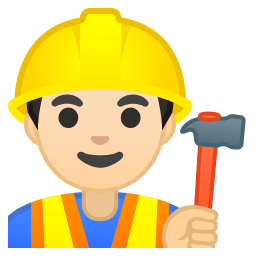
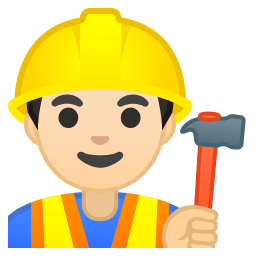

In [10]:
from typing import Dict, List, Tuple, Optional, Union # Ensure Union is imported

EMBEDDING_MODEL_NAME = "models/text-embedding-004"
LLM_MODEL_NAME = "models/gemini-2.0-flash"
# ---------------------------------------------------------------------------

def run_energy_comparison_analysis(
    target_home_id: int,
    month: str,
    original_df: pd.DataFrame,
    all_summaries_df: pd.DataFrame,
    embedding_model: str = EMBEDDING_MODEL_NAME,
    llm_model: str = LLM_MODEL_NAME,
    k_similar: int = 5
) -> Optional[Dict]:
    """
    Orchestrates the process of comparing a target home's energy usage for a specific month.

    Steps:
    1. Filters summaries for the specified month.
    2. Generates embeddings for the monthly summaries.
    3. Calculates similarity between the target home and others.
    4. Generates a comparative summary using an LLM.

    Args:
        target_home_id: The ID of the home to analyze.
        month: The month to analyze (e.g., "2023-01").
        original_df: The raw DataFrame with detailed timestamped energy readings.
        all_summaries_df: DataFrame containing all monthly summaries.
                          Requires 'year_month', 'Home ID', 'Summary Text' columns.
        embedding_model: Name of the embedding model to use.
        llm_model: Name of the generative LLM to use for summarization.
        k_similar: Number of top/bottom similar homes to find and potentially use.

    Returns:
        A dictionary containing 'top_similar', 'bottom_similar', and 'llm_summary'
        if successful, otherwise None.
    """
    print(f"\n--- Starting Analysis for Home {target_home_id}, Month {month} ---")

    # --- 1. Filter Data for the Month ---
    if 'year_month' not in all_summaries_df.columns:
        print(f"Error: DataFrame missing required 'year_month' column.")
        return None
    if 'year_month' not in original_df.columns:
        print(f"Error: Original DataFrame missing required 'year_month' column.")
        return None

    month_summaries_df = all_summaries_df[all_summaries_df['year_month'] == month].copy()
    if month_summaries_df.empty:
        print(f"Error: No summary data found for month {month}.")
        return None
    #print(f"Found {len(month_summaries_df)} summaries for month {month}.")

    # --- Filter original data for the specific month ---
    month_original_df = original_df[original_df['year_month'] == month].copy()
    if month_original_df.empty:
         print(f"Warning: No *original* detailed data found for month {month}, visualizations might be limited.")

     # --- Check if target home has data in the original df for this month ---
    target_monthly_original_data = month_original_df[month_original_df['Home ID'] == target_home_id]
    if target_monthly_original_data.empty:
        print(f"Warning: Target Home {target_home_id} has no detailed data in original_df for {month}. Cannot generate visualizations.")
    else:
        # --- Generate Target Home Visualization ---
        print("\n--- Generating Target Home Visualization ---")
        plot_target_appliance_breakdown(target_monthly_original_data, target_home_id, month)

    # --- 2. Generate Embeddings ---
    embeddings = None
    summaries = None
    try:
        # Assuming generate_embeddings_efficiently handles its own internal errors/logging
        embeddings, summaries = generate_embeddings_efficiently(
            summary_df=month_summaries_df,
            model_name=embedding_model
        )
        if not embeddings:
            print(f"Error: Embedding generation failed or returned empty for month {month}.")
            return None
        #print(f"Successfully generated {len(embeddings)} embeddings.")

    except Exception as e:
        print(f"Critical Error during embedding generation: {type(e).__name__}: {e}")
        return None

    # --- 3. Calculate Similarities ---
    top_similar = None
    bottom_similar = None
    try:
        # Assuming get_embedding_similarities handles target ID not found error etc.
        top_similar, bottom_similar = get_embedding_similarities(
            target_home_id=target_home_id,
            all_embeddings=embeddings,
            k=k_similar
        )
        if top_similar is None: # Check if function signaled an error
             print(f"Error: Failed to get similarities (e.g., target home missing in embeddings).")
             return None
        #print(f"Successfully calculated similarities.")
        top_bott_similar= top_similar+bottom_similar
        #print(top_bott_similar,top_similar)
    except ValueError as ve:
         print(f"Error during similarity calculation: {ve}")
         return None
    except TypeError as te:
         print(f"Error during similarity calculation (embedding format?): {te}")
         return None
    except Exception as e:
        print(f"Critical Error during similarity calculation: {type(e).__name__}: {e}")
        return None
# --- 4. Generate LLM Comparison Summary ---
    llm_summary = None
    try:
        if not top_bott_similar:
            print("Skipping LLM summary as no similar homes were found.")
            llm_summary = "No similar homes found for comparison."
        else:
            # Assuming generate_llm_comparison handles its own internal errors/logging
            llm_summary = generate_llm_comparison(
                target_home_id=target_home_id,
                top_matches=top_bott_similar,
                all_summaries=summaries, # Pass the summaries dict from embedding step
                model_name=llm_model,
                max_similar_to_include=10 # Example: Limit context for LLM
            )
            if llm_summary is None:
                print("LLM summary generation failed or returned None.")
                llm_summary = "Failed to generate LLM comparison summary."
            else:
                print("Successfully generated LLM comparison summary.")

    except Exception as e:
        print(f"Critical Error during LLM summary generation: {type(e).__name__}: {e}")
        llm_summary = f"Error during LLM summary generation: {e}"


    # --- 5. Consolidate and Return Results ---
    analysis_results = {
        "target_home_id": target_home_id,
        "month": month,
        "top_similar": top_bott_similar if top_bott_similar is not None else [],
        "bottom_similar": top_bott_similar if top_bott_similar is not None else [],
        "llm_summary": llm_summary if llm_summary is not None else "LLM analysis step failed or was skipped."
    }

     # --- Display Results ---
    if analysis_results:
        print("\n--- Analysis Results ---")
        print(f"Target Home: {analysis_results['target_home_id']}")
        print(f"Month: {analysis_results['month']}")
        if analysis_results['top_similar']:
            print(f"\nTop {len(analysis_results['top_similar'])} Similar Homes:")
            for home_id, score in analysis_results['top_similar']:
                print(f"  ID: {home_id}, Similarity: {score:.4f}")
            else:
                print("\nNo similar homes found for comparison.")
            # Optional: Print bottom similar
            # if analysis_results['bottom_similar']:
            #    print(f"\nBottom {len(analysis_results['bottom_similar'])} Similar Homes:")
            #    for home_id, score in analysis_results['bottom_similar']:
            #        print(f"  ID: {home_id}, Score: {score:.4f}")
            
            print("\nLLM Comparison Summary:")
            llm_output = analysis_results.get('llm_summary', "Summary not generated.")
            # Attempt to extract only final summary if CoT reasoning is present
            summary_parts = llm_output.split("Output:**") # Adjust split keyword based on LLM output format
            final_summary_text = summary_parts[-1].strip() if len(summary_parts) > 1 else llm_output
            print(final_summary_text if final_summary_text else "Summary not generated or empty.")
            
        else:
            print(f"\nAnalysis could not be completed for Home {target_home_id}, Month {month_str}. Please check previous error messages.")
            
    # --- Generate Comparison Visualizations ---
    # Initialize variables used in plots to avoid potential NameErrors if the 'if' block is skipped
    target_total_kwh = None
    avg_similar_total_kwh = None
    target_appliance_kwh = pd.Series(dtype=float)
    similar_appliance_kwh_avg = pd.Series(dtype=float)
    similar_individual_kwh_filtered = {}
    similar_house_size= {}
    target_house_size = None
    #household_sizes={}

    if top_bott_similar and not target_monthly_original_data.empty: # Only plot if we have similar homes AND target data
        print("\n--- Generating Comparison Visualizations ---")
        similar_home_ids = [home_id for home_id, score in top_bott_similar]
        num_similar = len(similar_home_ids)
        

        # Get original data for similar homes for the specific month
        similar_homes_monthly_original_data = month_original_df[month_original_df['Home ID'].isin(similar_home_ids)]
        
        if not similar_homes_monthly_original_data.empty:
            # --- Calculate Metrics for Comparison ---
            # Household size
            for key, text in summaries.items():
                match = re.search(r'Household Size:\s*(\d+)', text)
                if match:
                    if key in similar_home_ids: 
                        similar_house_size[key] = int(match.group(1))
                    elif key == target_home_id:
                        #print (key)
                        target_house_size  = int(match.group(1))
                else:
                    None
            #similar_house_size  = {hid: df_group['Household Size'].mode()[0]for hid, df_group in similar_homes_monthly_original_data.groupby('Home ID')} 
            #print(f'from monthy PD: {similar_house_size}')
            #target_house_size  = target_monthly_original_data['Household Size'].mode()[0]
            #print(f'target{target_house_size}')


  
            # Target Total kWh
            target_total_kwh = target_monthly_original_data['Energy Consumption (kWh)'].sum()

            # Average Total kWh for Similar Homes
            # *** Ensure this line is present and correctly indented ***
            similar_homes_totals = similar_homes_monthly_original_data.groupby('Home ID')['Energy Consumption (kWh)'].sum()
            avg_similar_total_kwh = similar_homes_totals.mean() if not similar_homes_totals.empty else 0 # Avoid NaN if empty

            # Target Appliance Breakdown
            target_appliance_kwh = target_monthly_original_data.groupby('Appliance Type')['Energy Consumption (kWh)'].sum()

            # Average Appliance Breakdown for Similar Homes
            # Group by home AND appliance, sum, then average across homes for each appliance
            similar_appliance_kwh_sum = similar_homes_monthly_original_data.groupby(['Home ID', 'Appliance Type'])['Energy Consumption (kWh)'].sum().reset_index()
            similar_appliance_kwh_avg = similar_appliance_kwh_sum.groupby('Appliance Type')['Energy Consumption (kWh)'].mean()

            # --- Call Plotting Functions ---
            # Plot comparing Target vs AVERAGE Similar
            if target_total_kwh is not None and avg_similar_total_kwh is not None:
                 plot_comparison_total_kwh(target_total_kwh, avg_similar_total_kwh, target_home_id, month, num_similar)

            # --- Call Individual Comparison Plot ---
            # Create dict of {similar_id: similar_total_kwh}
            similar_individual_kwh = similar_homes_totals.to_dict()
            # Ensure we only include the ones from the top_similar list if there's a mismatch somehow
            similar_individual_kwh_filtered = {hid: similar_individual_kwh.get(hid)
                                               for hid in similar_home_ids if hid in similar_individual_kwh}
            similar_house_size= {hid: similar_house_size[hid] for hid in similar_individual_kwh_filtered if hid in similar_house_size}
            #print(f'similar{similar_individual_kwh_filtered }')
            #print(f'similar{similar_house_size}')

            if similar_individual_kwh_filtered and target_total_kwh is not None: # Check if we have data after filtering
                 # Ensure plot_individual_comparison_kwh is defined correctly elsewhere
                 plot_individual_comparison_kwh(target_home_id, target_total_kwh, similar_individual_kwh_filtered,target_house_size,similar_house_size, month)
            else:
                 print("Warning: Could not retrieve sufficient individual kWh data for the individual comparison plot.")

            # Plot comparing top appliances (Target vs AVERAGE Similar)
            if not target_appliance_kwh.empty and not similar_appliance_kwh_avg.empty:
                # Ensure plot_comparison_top_appliances is defined correctly elsewhere
                plot_comparison_top_appliances(target_appliance_kwh, similar_appliance_kwh_avg, target_home_id, month, num_similar, top_n=5)

        else:
            print(f"Warning: No detailed original data found for the similar homes ({similar_home_ids}) in month {month}. Skipping comparison plots.")

    
    print(f"--- Analysis Complete for Home {target_home_id}, Month {month} ---")
    return analysis_results



**Function call to generate energy usage plots for target home and similar homes.**

* **Pie Chart** of appliance-level energy breakdown.
* **Bar Chart** comparing total energy usage vs. similar homes.
* **Grouped Bar Chart** for top appliances used vs. similar homes.
* **Individual Bar Chart** comparing total energy of the target home against each similar home.


In [11]:
# Functions definitions for generating plots for target home and similar homes data.
def plot_target_appliance_breakdown(target_monthly_data: pd.DataFrame, target_home_id: int, month: str):
    """
    Generates a pie chart showing the appliance energy consumption breakdown
    for the target home in the specified month.
    """
    if target_monthly_data.empty:
        print("No data to plot for target home appliance breakdown.")
        return

    appliance_usage = target_monthly_data.groupby('Appliance Type')['Energy Consumption (kWh)'].sum().sort_values(ascending=False)
    # Filter out very small values for clarity
    appliance_usage = appliance_usage[appliance_usage > appliance_usage.sum() * 0.01] # Keep appliances > 1% of total

    if appliance_usage.empty:
        print("No significant appliance usage to plot for target home.")
        return

    plt.figure(figsize=(8, 8))
    plt.pie(appliance_usage, labels=appliance_usage.index, autopct='%1.1f%%', startangle=140)
    plt.title(f'Target Home {target_home_id} - Appliance Energy Breakdown ({month})')
    plt.ylabel('') # Hide the default 'Energy Consumption (kWh)' label on the side
    plt.tight_layout()
    plt.show()

def plot_comparison_total_kwh(target_kwh: float, avg_similar_kwh: float, target_home_id: int, month: str, num_similar: int):
    """
    Generates a bar chart comparing the total monthly kWh of the target home
    against the average of its similar homes.
    """
    if target_kwh is None or avg_similar_kwh is None:
        print("Missing data for total kWh comparison plot.")
        return

    labels = [f'Target Home {target_home_id}', f'Average of {num_similar} Similar Homes']
    values = [target_kwh, avg_similar_kwh]

    plt.figure(figsize=(6, 4))
    bars = plt.bar(labels, values, color=['skyblue', 'lightgreen'])
    plt.ylabel('Total Energy Consumption (kWh)')
    plt.title(f'Total Monthly Energy Consumption Comparison ({month})')
    # Add values on top of bars
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2.0, yval, f'{yval:.1f} kWh', va='bottom', ha='center') # Adjust position slightly above bar
    plt.xticks(rotation=0, ha='center') # Ensure labels are readable
    plt.tight_layout()
    plt.show()

def plot_comparison_top_appliances(target_appliances: pd.Series, similar_appliances_avg: pd.Series, target_home_id: int, month: str, num_similar: int, top_n: int = 5):
    """
    Generates grouped bar charts comparing the consumption of top N appliances
    between the target home and the average of similar homes.
    """
    if target_appliances.empty or similar_appliances_avg.empty:
        print("Missing data for top appliance comparison plot.")
        return

    # Combine the series into a DataFrame for easier plotting
    comparison_df = pd.DataFrame({
        f'Target Home {target_home_id}': target_appliances,
        f'Avg. Similar ({num_similar})': similar_appliances_avg
    }).fillna(0) # Fill missing appliances in either series with 0

    # Determine the top N appliances based on the *target* home's usage
    # (or combined usage, depending on desired focus)
    # Here, we focus on target's top appliances
    top_appliances_list = target_appliances.nlargest(top_n).index.tolist()

    # Filter the comparison DataFrame to include only these top appliances
    # and potentially others that are significant in the similar homes
    plot_df = comparison_df.loc[top_appliances_list]

    # If no appliances meet the criteria
    if plot_df.empty:
        print(f"No top {top_n} appliances found with significant usage for comparison.")
        return

    # Plotting
    ax = plot_df.plot(kind='bar', figsize=(10, 6), width=0.8) # Adjust width as needed
    plt.ylabel('Average Monthly Energy Consumption (kWh)')
    plt.title(f'Comparison of Top {len(plot_df)} Appliance Usage ({month})')
    plt.xlabel('Appliance Type')
    plt.xticks(rotation=45, ha='right')
    plt.legend(title='Home Category')
    plt.tight_layout()
    plt.show()

def plot_individual_comparison_kwh(target_home_id: int, target_kwh: float, top_similar_data: Dict[int, float],target_hsize: int,
                                   top_similar_hsize: Dict[int, int], month: str):
    """
    Generates a bar chart comparing the total monthly kWh of the target home
    against EACH of its top similar homes individually.

    Args:
        target_home_id: ID of the target home.
        target_kwh: Total kWh for the target home for the month.
        top_similar_data: Dictionary mapping {similar_home_id: total_kwh} for top similar homes.
        month: The month being analyzed (e.g., "2023-01").
    """
    if target_kwh is None or not top_similar_data:
        print("Missing data for individual kWh comparison plot.")
        return

    # Prepare data for plotting
    home_ids = [f'Target\n({target_home_id})'] + [f'Similar\n({hid})' for hid in top_similar_data.keys()]
    kwh_values = [target_kwh] + list(top_similar_data.values())
    colors = ['skyblue'] + ['lightcoral'] * len(top_similar_data) # Different color for target
   
    house_size = [target_hsize] + list(top_similar_hsize.values())


     
    plt.figure(figsize=(max(6, len(home_ids) * 1.5), len(home_ids))) # Adjust width based on number of bars
    bars = plt.bar(home_ids, kwh_values, color=colors)

    plt.ylabel('Total Energy Consumption (kWh)')
    plt.title(f'Target vs. Individual Similar Homes - Total Monthly Energy and Household Size ({month})')
    plt.xticks(rotation=0, ha='center') # Keep labels horizontal if possible

    
    # Add values on top of bars
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2.0, yval, f'{yval:.1f}', va='bottom', ha='center', fontsize=9) # Adjust position slightly above bar
    
    # Create second y-axis for Household Size
    ax2 = plt.twinx()
    ax2.plot(home_ids, house_size, color='green', marker='o', linewidth=2, label='Household Size')
    ax2.set_ylabel('Household Size')
    ax2.tick_params(axis='y')
    # Add text labels on line points
    for i, value in enumerate(house_size):
        ax2.text(home_ids[i], value + 0.2, f'{value}', ha='center', va='bottom', fontsize=9, color='green')
    
    plt.tight_layout()
    plt.show()

## 💡 Interactive Exploration: 
### Your Personalized Energy Insights

The tool facilitates an interactive energy benchmarking analysis for households, where users can input a target home ID and a specific month to compare energy consumption with similar homes. Ensuring that all inputs and outputs are properly validated, with comprehensive error handling in place.

* **Main Program Loop:** The user is prompted to enter a Home ID and Month (YYYY-MM) for analysis.The loop continues until the user types 'quit' to exit.
* **Analysis Execution:** Calls the function run_energy_comparison_analysis to generate results.The analysis compares the target home's energy consumption against similar homes and provides a comparison summary.
* **Results Display:** Displays the top similar homes with their similarity scores.Shows a textual summary generated by a language model (LLM) for a more detailed comparison.

--- Watt-Seer-Compare: Household Energy Benchmarking ---



Enter Target Home ID and Month (YYYY-MM) separated by space (or type 'quit' to exit): 
 25 2023-10



--- Starting Analysis for Home 25, Month 2023-10 ---

--- Generating Target Home Visualization ---


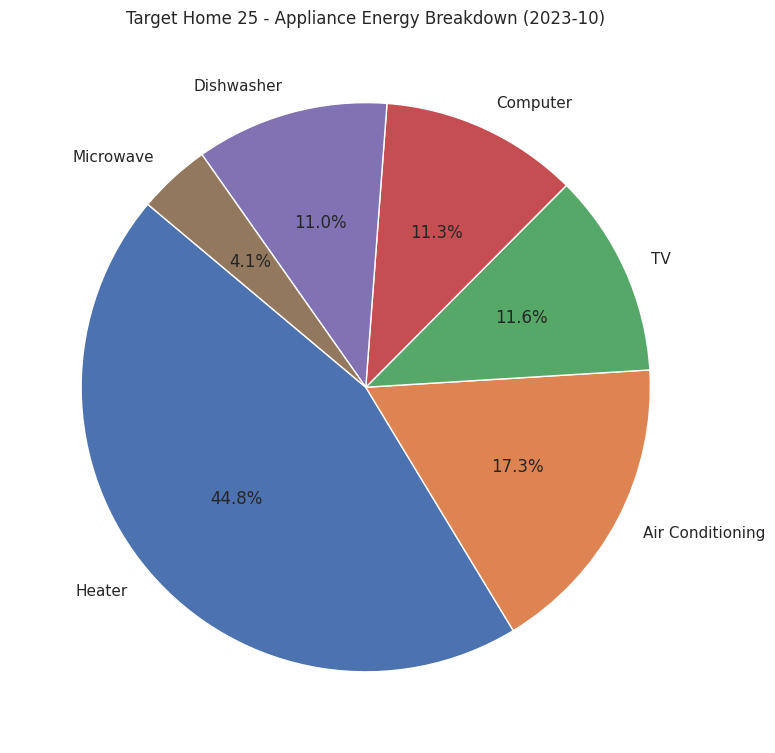

Starting LLM comparison summary generation...
Successfully generated LLM comparison summary.

--- Analysis Results ---
Target Home: 25
Month: 2023-10

Top 10 Similar Homes:
  ID: 478, Similarity: 0.9736
  ID: 235, Similarity: 0.9734
  ID: 293, Similarity: 0.9732
  ID: 139, Similarity: 0.9726
  ID: 398, Similarity: 0.9693
  ID: 314, Similarity: 0.9124
  ID: 67, Similarity: 0.9141
  ID: 66, Similarity: 0.9143
  ID: 421, Similarity: 0.9143
  ID: 80, Similarity: 0.9152

No similar homes found for comparison.

LLM Comparison Summary:
**Reasoning:**

1.  **Target Home Profile:** Home ID 25 consumed 29.1 kWh in October 2023. It's a two-person household with an average temperature of 19.6°C during the fall season. The primary energy consumption drivers are the heater (12.9 kWh) and air conditioning (5.0 kWh), followed by TV, Computer, and Dishwasher.

2.  **Common Themes:** The most similar homes (similarity scores > 0.96) share several characteristics with the Target Home.
    *   **Season:**

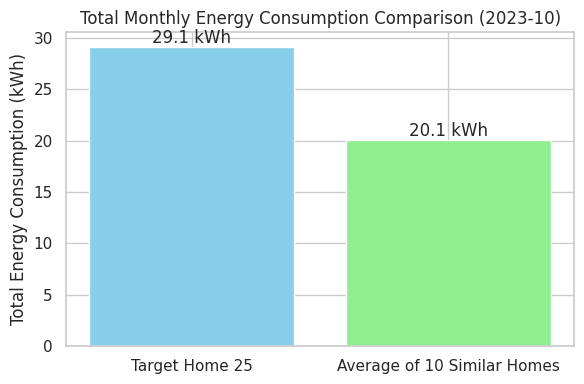

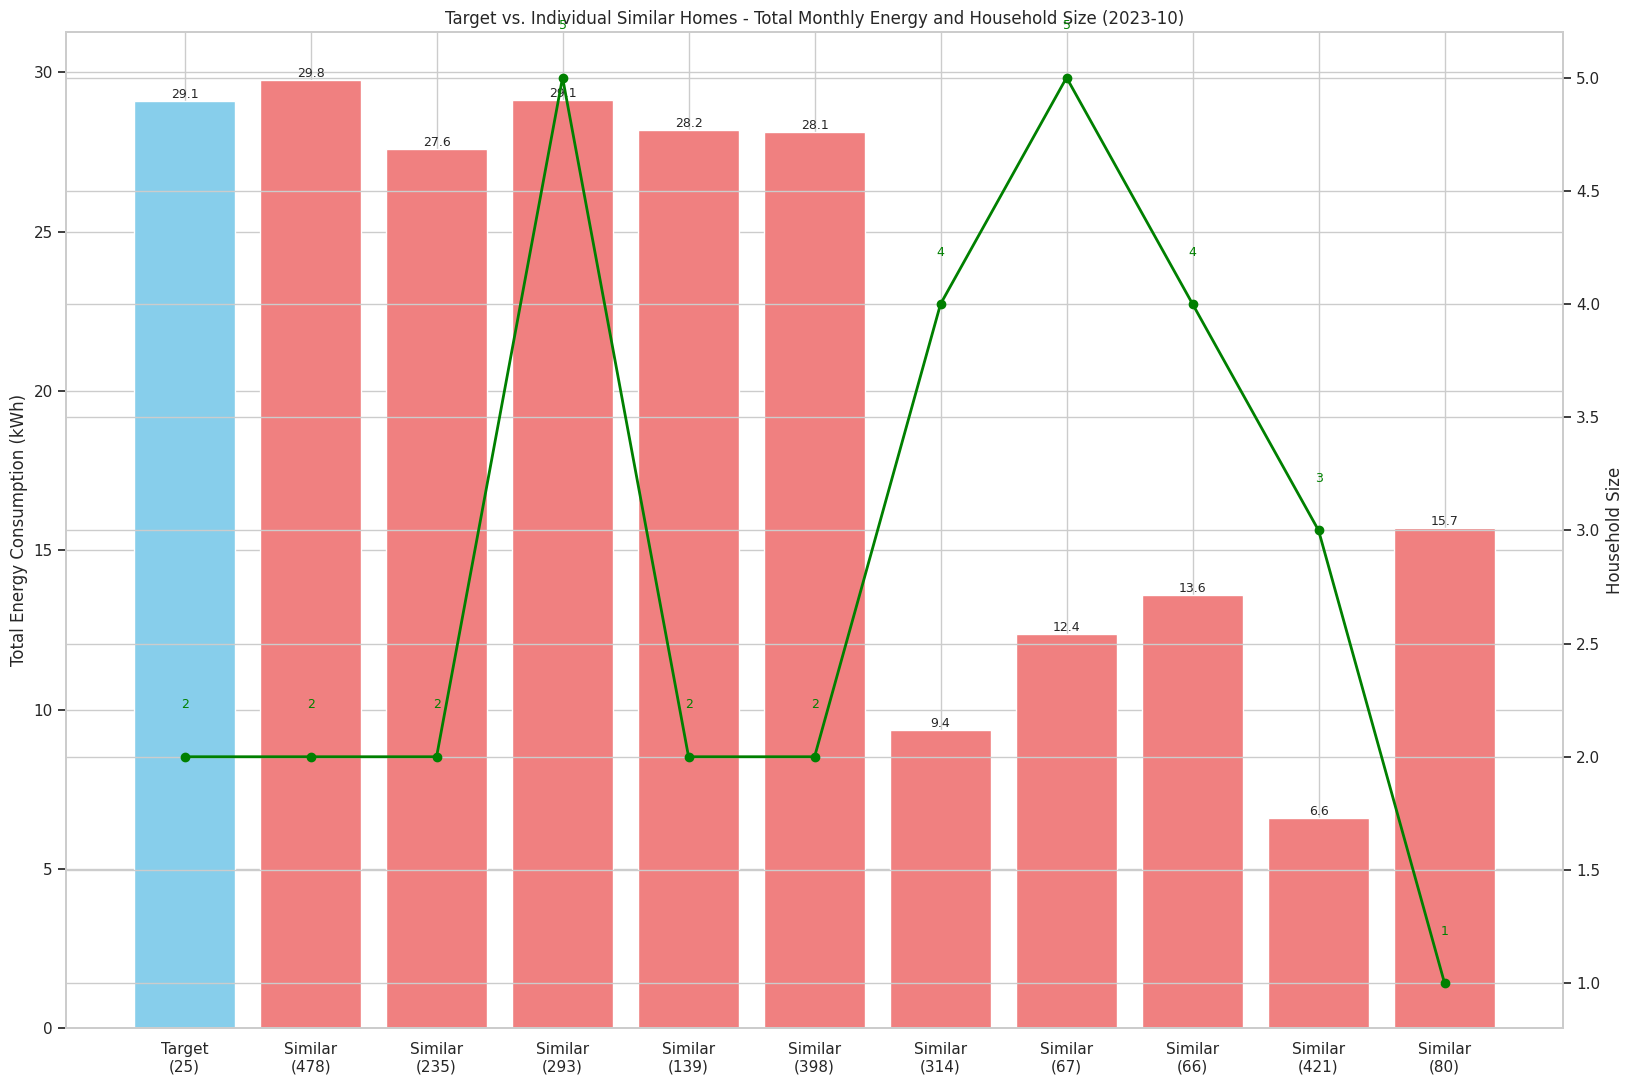

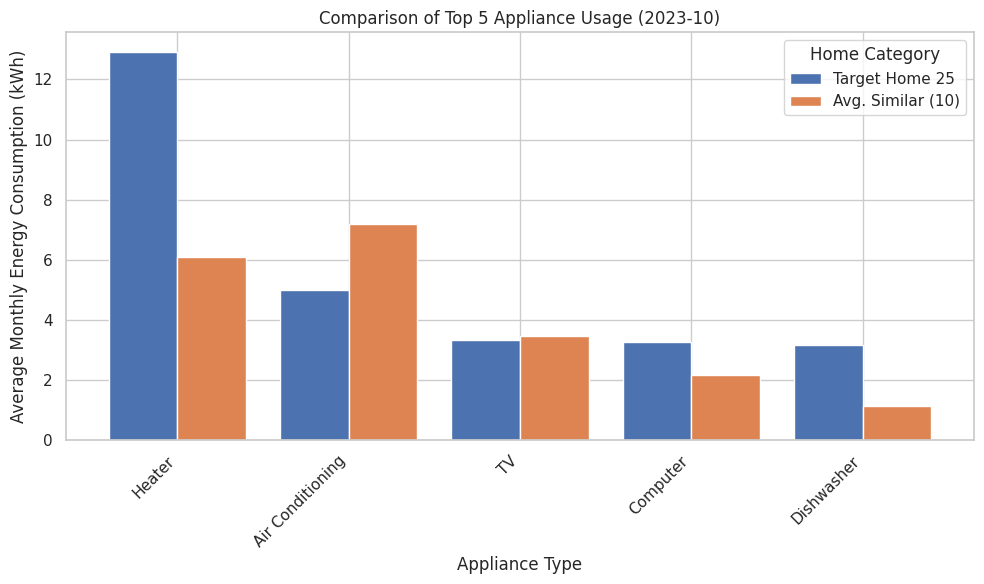

--- Analysis Complete for Home 25, Month 2023-10 ---




In [ ]:
# Main Program: Loop to get comparsion summary for house until  'quit'
import re # For regular expression validation of month format
import sys # To exit gracefully if file not found


# Define constants if not defined elsewhere
EMBEDDING_MODEL_NAME = "models/text-embedding-004"
LLM_MODEL_NAME = "models/gemini-2.0-flash"

def main():
    print("--- Watt-Seer-Compare: Household Energy Benchmarking ---")

    """
    Main loop to get user input and run the energy comparison analysis.
    """
    
    # --- Main Interaction Loop ---
    while True:
        user_input = input("\nEnter Target Home ID and Month (YYYY-MM) separated by space (or type 'quit' to exit): \n").strip()

        if user_input.lower() == "quit":
            print("Exiting program.")
            break

        # --- Input Validation ---
        input_parts = user_input.split()
        if len(input_parts) != 2:
            print("Invalid input format. Please enter Home ID and Month (YYYY-MM) separated by a single space.")
            continue

        home_id_str, month_str = input_parts

        # Validate Home ID
        try:
            target_home_id = int(home_id_str)
            if target_home_id <= 0: # Basic sanity check
                 raise ValueError("Home ID must be a positive integer.")
        except ValueError:
            print(f"Invalid Home ID: '{home_id_str}'. Please enter a valid integer.")
            continue

        # Validate Month Format (YYYY-MM)
        if not re.match(r'^\d{4}-\d{2}$', month_str):
            print(f"Invalid Month format: '{month_str}'. Please use YYYY-MM format (e.g., 2023-01).")
            continue
        # More strict validation (optional): check if month/year are realistic
        try:
            year, month_num = map(int, month_str.split('-'))
            if not (1 <= month_num <= 12):
                 raise ValueError("Month must be between 01 and 12.")
            # Add year range check if desired
        except ValueError as ve:
             print(f"Invalid date value in month '{month_str}': {ve}")
             continue


        # --- (Optional) Check if data exists before running full analysis ---
        target_exists = target_home_id in summary_df['Home ID'].values
        month_exists = month_str in summary_df['year_month'].values

        if not target_exists:
             print(f"Error: Target Home ID {target_home_id} not found in the loaded data.")
             continue
        if not month_exists:
             print(f"Error: Month {month_str} not found in the loaded data.")
             available_months_msg = f" Available months include: {', '.join(available_months[:5])}{'...' if len(available_months) > 5 else ''}" if available_months else ""
             print(available_months_msg)
             continue
        # --- End Optional Check ---


        # --- Run Analysis ---
        try:
            # Call the enhanced orchestrator function, passing original_df
            analysis_results = run_energy_comparison_analysis(
                target_home_id=target_home_id,
                month=month_str,
                original_df=df,
                all_summaries_df=summary_df
            )

           
        except Exception as e:
            print(f"\nAn unexpected error occurred during analysis: {type(e).__name__}: {e}")

        print("\n" + "="*50 + "\n") # Separator for next iteration

if __name__ == "__main__":
    main()